# TinyStories

In [ ]:
from torch import nn

from artifacts.core.artifact import Resources
from artifacts.core.resolve import resolve
from artifacts.core.SGD.training import LoopConfig, LRSchedule, OptimizerParameters, TrainingParameters
from artifacts.mappeddataset import MappedDataSet
from artifacts.sources import SourceURL
from artifacts.stages.pretraining import Pretraining
from artifacts.tokenizers.bpe import Tokenizer as BPETokenizer
from models.transformer import Transformer
from profiling.profile_events import aggregate_kernels, display_steps, events_to_rows, launch_chain
from profiling.step_report import build_report
from profiling.util import run_profile

In [2]:
HF = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main"
train = SourceURL(name="tinystories-train", url=f"{HF}/TinyStoriesV2-GPT4-train.txt")
valid = SourceURL(name="tinystories-valid", url=f"{HF}/TinyStoriesV2-GPT4-valid.txt")

tokenizer = BPETokenizer(
    vocab_size=10000,
    special_tokens=("<|endoftext|>",),
    sources=(valid,),
    allocated_resources=Resources(cpu=4),
)

dataset = MappedDataSet.from_sources(
    tokenizer=tokenizer,
    train_sources=(train,),
    valid_sources=(valid,),
)

pretraining = Pretraining(
    run_id="BMTHENRUN",
    dataset=dataset,
    model=Transformer(
        vocab_size=tokenizer.vocab_size,
        d_model=128,
        d_ff=256,
        sequence_length=32,
        num_layers=4,
        num_heads=16,
        rope_theta=10000,
        dtype="torch.float32",
    ),
    training_parameters=TrainingParameters(
        total_steps=20000,
        batch_size=64,
        max_norm=1.0,
        lr_schedule=LRSchedule(
            max_learning_rate=3e-4,
            min_learning_rate=3e-5,
            warmup_iters=200,
            cosine_cycle_iters=5000,
        ),
        optimizer="torch.optim.AdamW",
        optimizer_parameters=OptimizerParameters(
            lr=3e-4,
            betas=(0.9, 0.95),
            weight_decay=0.1,
            eps=1e-8,
        ),
        seed=0,
    ),
    loop_config=LoopConfig(
        checkpoint_every=5000,
        val_every=200,
        gpu_check_every=200,
    ),
    allocated_resources=Resources(gpu_type="T4", gpu_count=1),
)

## Declare

In [3]:
for artifact in resolve(pretraining):
    print(f"{type(artifact).__name__:16} {artifact.artifact_path}")

SourceURL        sources/tinystories-train
SourceURL        sources/tinystories-valid
Tokenizer        tokenizers/bpe-10000-b46983c6f3
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-train
TokenizedSource  tokenized/bpe-10000-b46983c6f3/tinystories-valid
MappedDataSet    mappeddatasets/mapped-2be543ce28
Pretraining      runs/BMTHENRUN/pretraining/0-20000-4765773afc


In [ ]:
from local import declare_on_volume
report = declare_on_volume(pretraining, verbose=True, commit=True)  # commit=True publishes

sources/tinystories-train                         done  (drift: 73684a0 -> 4636bc7)
sources/tinystories-valid                         done  (drift: f9752b6 -> 4636bc7)
tokenizers/bpe-10000-b46983c6f3                   done  (drift: f9752b6 -> 4636bc7)
tokenized/bpe-10000-b46983c6f3/tinystories-train  done  (drift: f9752b6 -> 4636bc7)
tokenized/bpe-10000-b46983c6f3/tinystories-valid  done  (drift: f9752b6 -> 4636bc7)
mappeddatasets/mapped-2be543ce28                  done  (drift: f9752b6 -> 4636bc7)
runs/BMTHENRUN/pretraining/0-20000-4765773afc     already declared  (drift: f3a22b3 -> 4636bc7)

1 already declared, 6 done
ok -- everything already declared


## Benchmark

In [8]:
captured = run_profile(
    pretraining.allocated_resources,
    model_declaration=pretraining.model,
    training_parameters=pretraining.training_parameters,
    batch_size=pretraining.training_parameters.batch_size,
    warmup_steps=5,
    profile_steps=2,
    autocast=None,  # PretrainJob trains without autocast
    kernel_events=True,
    module_scopes=True,
    peak_memory=True,
    trace_memory=True,
)

profile call fc-01M5Y0KPCP78RSZXXAZ4NKDYSC
INFO profile: Transformer on Tesla T4, batch_size 64
INFO profile: warmup: 5 steps
INFO profile: step 0: 250.9 ms
INFO profile: step 1: 361.6 ms
INFO profile: done


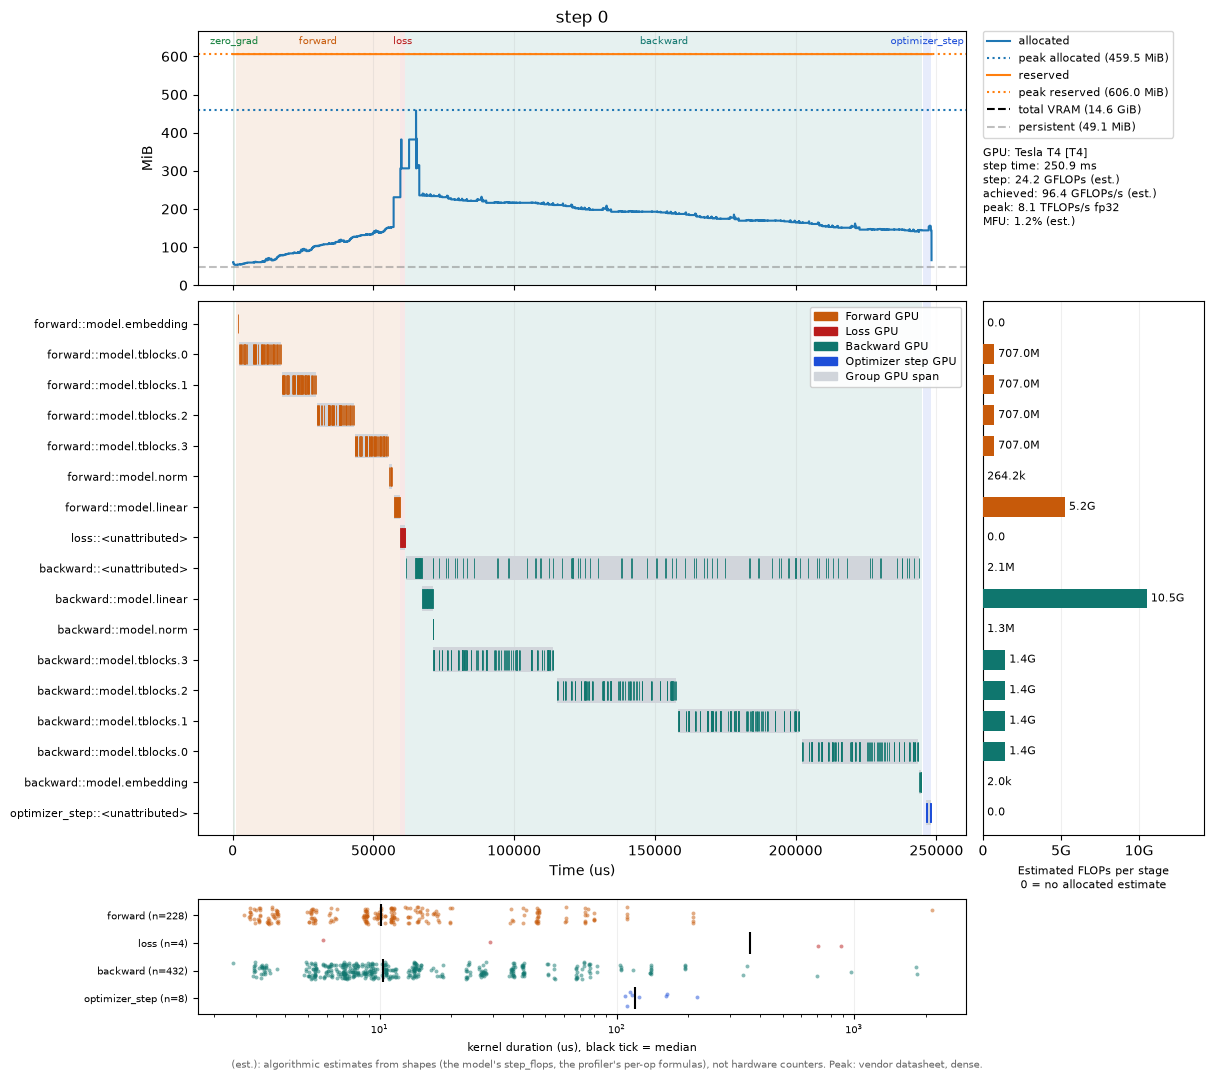

In [10]:
report = build_report(captured, depth=3)
display_steps(report, steps=[0])

In [11]:
step = max(captured["steps"])
rows = events_to_rows(captured["steps"][step]["events"])
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       12.480       12.480   
               model.linear                1     2118.161     2118.161   
               model.norm                  6       50.272      644.828   
               model.tblocks.0            55     1170.200    14121.787   
               model.tblocks.1            55     1191.960   207985.363   
               model.tblocks.2            55     1243.188    10982.001   
               model.tblocks.3            55     1248.950    11261.967   
loss           <unattributed>              4     1630.741     1634.325   
backward       <unattributed>             84     3135.081   100666.321   
               model.embedding             7       85.472      594.972   
               model.linear                2     3660.454     3665.894   
               model.norm                 15      154.943      185.246   
               model.tblocks.0            81     2220.880    23415.577   
               model.tblocks.1            81     2224.012    23150.299   
               model.tblocks.2            81     2224.528    23186.682   
               model.tblocks.3            81     2225.810    21898.820   
optimizer_step <unattributed>              8     1111.000     2101.297   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding     0.000000e+00  
               model.linear        5.242880e+09  
               model.norm          2.641920e+05  
               model.tblocks.0     7.070075e+08  
               model.tblocks.1     7.070075e+08  
               model.tblocks.2     7.070075e+08  
               model.tblocks.3     7.070075e+08  
loss           <unattributed>      0.000000e+00  
backward       <unattributed>      2.097152e+06  
               model.embedding     2.048000e+03  
               model.linear        1.048576e+10  
               model.norm          1.314816e+06  
               model.tblocks.0     1.416110e+09  
               model.tblocks.1     1.416110e+09  
               model.tblocks.2     1.416110e+09  
               model.tblocks.3     1.416110e+09  
optimizer_step <unattributed>      0.000000e+00

In [12]:
display(kernels[["name", "phase", "module_fqn", "owner_fqn", "gpu_start_us", "duration_us"]])

,name,phase,module_fqn,owner_fqn,gpu_start_us,duration_us
index,,,,,,
14,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,6159.088,12.480
2039,volta_sgemm_128x128_tn,forward,model.linear,model.linear,253384.651,2118.161
1987,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,252225.747,6.496
1990,"void at::native::reduce_kernel<512, 1, at::nat...",forward,model.norm,model.norm,252367.378,14.464
1993,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,252479.761,3.104
...,...,...,...,...,...,...
8717,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,361094.378,160.671
8915,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,362168.642,115.935
8918,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,362340.481,126.879


In [13]:
kernel_id = report["steps"][str(step)]["kernels"]["id"][0]
display(launch_chain(rows, kernel_id, format=True))

,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,5420.749,255537.258,<NA>,7683,0,0,[],[]
7,forward::model,user_annotation,DeviceType.CPU,5522.520,253679.856,5,7684,0,0,[],[]
8,forward::model.embedding,user_annotation,DeviceType.CPU,5658.422,6388.264,7,7685,0,0,[],[]
9,aten::index,cpu_op,DeviceType.CPU,5830.263,6176.896,8,7686,0,0,"[[10000, 128], []]","[float, ]"
13,cudaLaunchKernel,cuda_runtime,DeviceType.CPU,6053.240,6167.852,9,15931,7686,0,[],[]
14,"void at::native::vectorized_gather_kernel<16, ...",kernel,DeviceType.CUDA,6159.088,6171.568,13,15931,7686,0,[],[]
